In [1]:

import pandas as pd

print("Future Interns - Task 1")
print("Business Sales Performance Analytics")
print("My first data analytics project is starting!")

print("\nPandas version:", pd.__version__)


Future Interns - Task 1
Business Sales Performance Analytics
My first data analytics project is starting!

Pandas version: 2.2.3


In [2]:

import pandas as pd

# Create a sample sales dataset
data = {
    "Date": [
        "2026-01-05", "2026-01-12", "2026-02-03",
        "2026-02-15", "2026-03-02", "2026-03-18",
        "2026-04-07", "2026-04-20", "2026-05-10",
        "2026-05-22"
    ],
    "Product": [
        "Laptop", "Mobile", "Headphones", "Laptop",
        "Mobile", "Keyboard", "Laptop", "Headphones",
        "Mobile", "Keyboard"
    ],
    "Category": [
        "Electronics", "Electronics", "Accessories",
        "Electronics", "Electronics", "Accessories",
        "Electronics", "Accessories", "Electronics",
        "Accessories"
    ],
    "Region": [
        "South", "North", "East", "West", "South",
        "North", "East", "West", "South", "North"
    ],
    "Quantity": [2, 5, 10, 1, 4, 8, 3, 6, 7, 12],
    "Unit_Price": [50000, 15000, 1000, 50000, 15000,
                   800, 50000, 1000, 15000, 800],
    "Profit": [10000, 7500, 2000, 5000, 6000,
               1600, 15000, 1200, 10500, 2400]
}

df = pd.DataFrame(data)

# Calculate total sales
df["Sales"] = df["Quantity"] * df["Unit_Price"]

# Display the dataset
display(df)


,Date,Product,Category,Region,Quantity,Unit_Price,Profit,Sales
0,2026-01-05,Laptop,Electronics,South,2,50000,10000,100000
1,2026-01-12,Mobile,Electronics,North,5,15000,7500,75000
2,2026-02-03,Headphones,Accessories,East,10,1000,2000,10000
3,2026-02-15,Laptop,Electronics,West,1,50000,5000,50000
4,2026-03-02,Mobile,Electronics,South,4,15000,6000,60000
5,2026-03-18,Keyboard,Accessories,North,8,800,1600,6400
6,2026-04-07,Laptop,Electronics,East,3,50000,15000,150000
7,2026-04-20,Headphones,Accessories,West,6,1000,1200,6000
8,2026-05-10,Mobile,Electronics,South,7,15000,10500,105000
9,2026-05-22,Keyboard,Accessories,North,12,800,2400,9600


In [3]:

# 1. Calculate total sales and profit
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()

print("===== SALES PERFORMANCE SUMMARY =====")
print(f"Total Revenue: ₹{total_sales:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Total Units Sold: {total_quantity}")

# 2. Find sales by product
product_sales = df.groupby("Product")["Sales"].sum()
product_sales = product_sales.sort_values(ascending=False)

print("\n===== SALES BY PRODUCT =====")
display(product_sales.reset_index())

# 3. Find profit by product
product_profit = df.groupby("Product")["Profit"].sum()
product_profit = product_profit.sort_values(ascending=False)

print("\n===== PROFIT BY PRODUCT =====")
display(product_profit.reset_index())


===== SALES PERFORMANCE SUMMARY =====
Total Revenue: ₹572,000.00
Total Profit: ₹61,200.00
Total Units Sold: 58

===== SALES BY PRODUCT =====


,Product,Sales
0,Laptop,300000
1,Mobile,240000
2,Keyboard,16000
3,Headphones,16000



===== PROFIT BY PRODUCT =====


,Product,Profit
0,Laptop,30000
1,Mobile,24000
2,Keyboard,4000
3,Headphones,3200


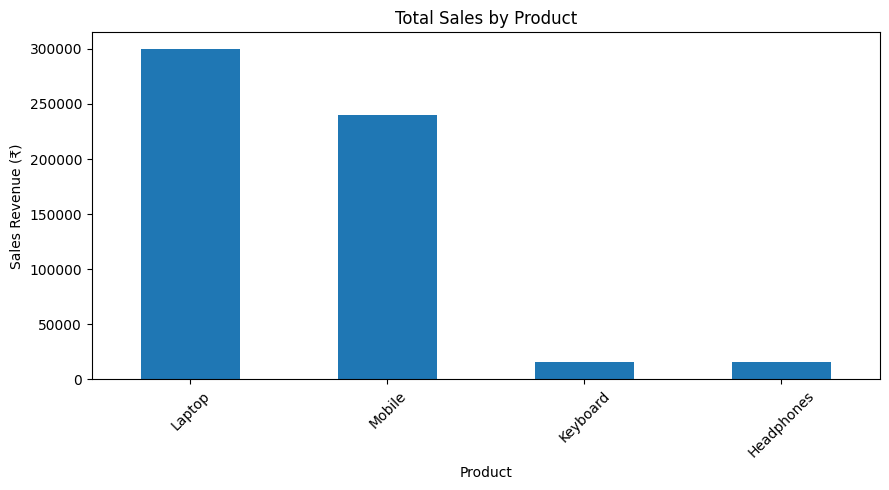

In [4]:
import matplotlib.pyplot as plt

# Calculate sales by product
product_sales = df.groupby("Product")["Sales"].sum()
product_sales = product_sales.sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(9, 5))
product_sales.plot(kind="bar")

plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Sales Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

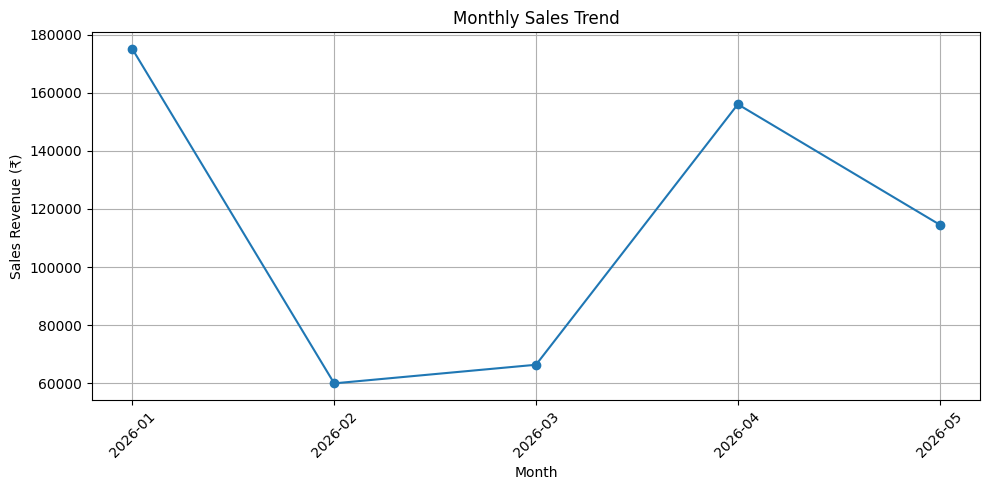

Monthly Sales:


,Date,Sales
0,2026-01,175000
1,2026-02,60000
2,2026-03,66400
3,2026-04,156000
4,2026-05,114600


In [5]:
# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Group sales by month
monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))["Sales"]
    .sum()
)

# Create a line chart
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales Revenue (₹)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Display monthly sales values
print("Monthly Sales:")
display(monthly_sales.rename("Sales").reset_index())


===== SALES BY REGION =====


,Region,Sales
0,South,265000
1,East,160000
2,North,91000
3,West,56000


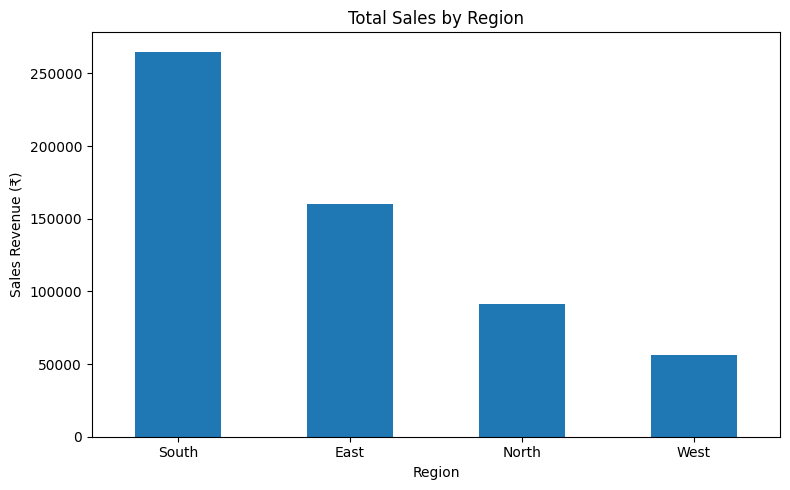

Overall Profit Margin: 10.70%


In [6]:
# Calculate total sales by region
region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("===== SALES BY REGION =====")
display(region_sales.reset_index())

# Create a bar chart
plt.figure(figsize=(8, 5))
region_sales.plot(kind="bar")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Calculate profit margin
profit_margin = (total_profit / total_sales) * 100

print(f"Overall Profit Margin: {profit_margin:.2f}%")

===== CATEGORY PERFORMANCE =====


,Total_Sales,Total_Profit,Units_Sold
Category,,,
Accessories,32000,7200,36
Electronics,540000,54000,22


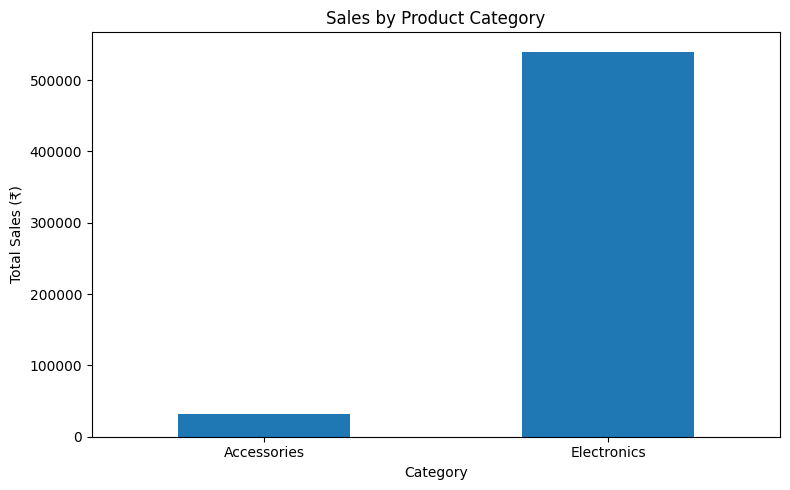

In [7]:

# Calculate sales and profit by category
category_summary = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum")
)

print("===== CATEGORY PERFORMANCE =====")
display(category_summary)

# Plot category sales
plt.figure(figsize=(8, 5))
category_summary["Total_Sales"].plot(kind="bar")

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



===== PROFIT BY PRODUCT =====


,Product,Profit
0,Laptop,30000
1,Mobile,24000
2,Keyboard,4000
3,Headphones,3200


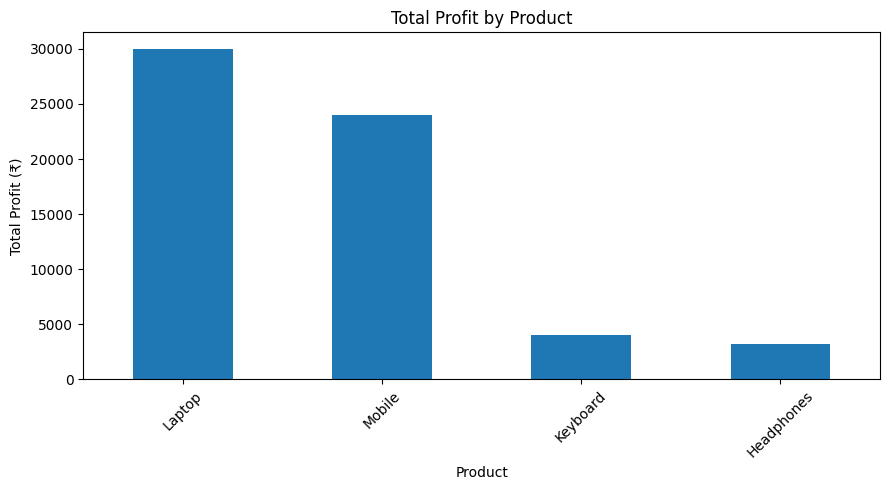

Total Sales: ₹572,000
Total Profit: ₹61,200
Profit Margin: 10.70%


In [8]:

# Calculate profit by product
profit_by_product = (
    df.groupby("Product")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print("===== PROFIT BY PRODUCT =====")
display(profit_by_product.reset_index())

# Create profit chart
plt.figure(figsize=(9, 5))
profit_by_product.plot(kind="bar")

plt.title("Total Profit by Product")
plt.xlabel("Product")
plt.ylabel("Total Profit (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Calculate profit margin
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

print(f"Total Sales: ₹{total_sales:,.0f}")
print(f"Total Profit: ₹{total_profit:,.0f}")
print(f"Profit Margin: {(total_profit / total_sales) * 100:.2f}%")


# Business Sales Performance Analytics

## 1. Project Objective
The objective of this project is to analyze sales data to understand product performance, regional sales, monthly revenue trends, and profitability.

## 2. Tools Used
- Python
- Pandas
- Matplotlib
- Google Colab

## 3. Key Findings
- Laptops generated the highest revenue among the products in the sample dataset.
- Mobile phones were the second-highest revenue contributor.
- The South region recorded the highest sales.
- Electronics generated substantially more revenue than Accessories.
- Monthly revenue fluctuated during the five-month sample period.
- Profit analysis showed that laptops contributed the highest total profit.

## 4. Business Recommendations
- Maintain sufficient inventory of high-performing products.
- Investigate customer demand and pricing opportunities for accessories.
- Study the sales strategies used in the highest-performing region.
- Monitor monthly sales trends to improve inventory planning.
- Evaluate profit margins before deciding on discounts and promotions.

## 5. Conclusion
This project demonstrates how Python-based data analysis and visualization can help businesses understand sales performance and identify opportunities for improvement.

**Data note:** The dataset used in this learning exercise is illustrative sample data. The findings are not based on actual company transactions.